Loaded LS_sim_no_noise_linear_friction: 500 steps
Loaded HNN_sim_no_noise_linear_friction: 500 steps


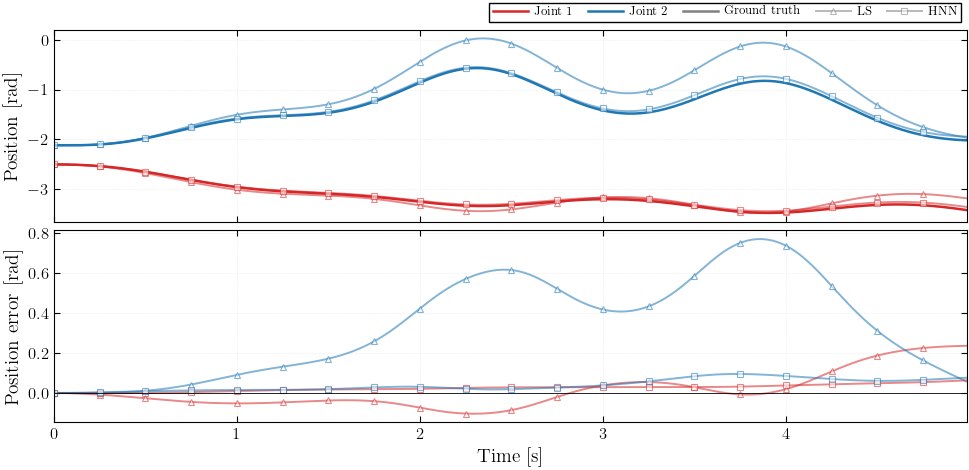

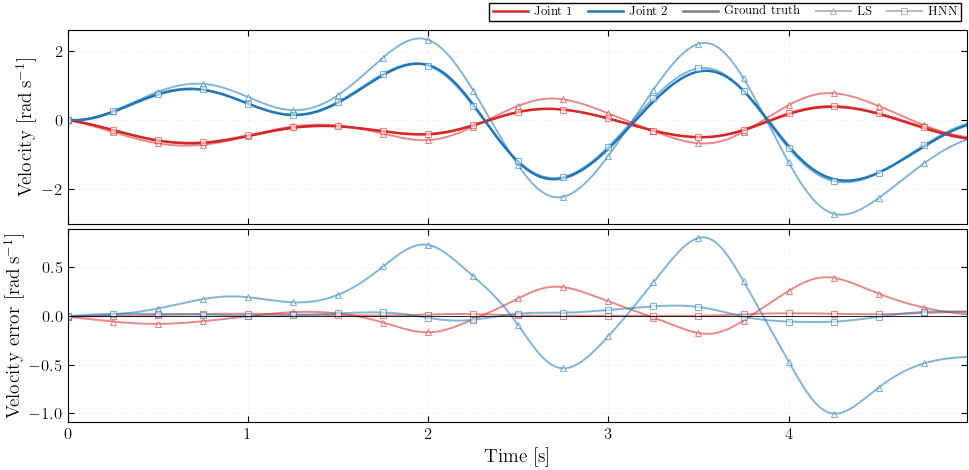

In [24]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# IEEE STYLE
# ============================================================
mpl.rcdefaults()
mpl.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "legend.fontsize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.top": True,
    "ytick.right": True,
    "axes.grid": True,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.linestyle": ":",
    "lines.linewidth": 1.4,
    "legend.frameon": True,
    "legend.framealpha": 1.0,
    "legend.edgecolor": "black",
    "legend.fancybox": False,
    "legend.handlelength": 2.8,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
})

# ============================================================
# LOAD MODELS
# ============================================================
model_files = [
    "results_LS_sim_no_noise_linear_friction.npz",
    "results_HNN_sim_no_noise_linear_friction.npz",
    # "results_baseline.npz",   # add more as needed
]



models = {}
for f in model_files:
    d = np.load(f, allow_pickle=True)
    name = str(d["model_name"])
    models[name] = d
    print(f"Loaded {name}: {len(d['true_theta1'])} steps")

ref = list(models.values())[0]
dt = float(ref["dt"])
T = min(len(ref["true_theta1"]),
        *[len(m["pred_theta1"]) for m in models.values()])
time = np.arange(T) * dt

# ============================================================
# VISUAL ENCODING
#   Colour = joint  (red = joint 1, blue = joint 2)
#   Truth  = full opacity, solid, no marker
#   HNN    = reduced alpha, square markers
#   LS     = reduced alpha, triangle markers
# ============================================================
C_J1 = "#D62728"   # red
C_J2 = "#1F77B4"   # blue

GT_LW = 1.8
MD_LW = 1.4
ALPHA_MODEL = 0.55

N_MARKER = max(1, T // 20)

MODEL_CFG = {
    # name: (marker, alpha, display_label)
    "LS_sim_no_noise_linear_friction":  ("^", ALPHA_MODEL, "LS"),
    "HNN_sim_no_noise_linear_friction": ("s", ALPHA_MODEL, "HNN"),
}

# Fallback
_FALLBACK_MK = ["^", "s", "D", "v", "o"]
for i, name in enumerate(models):
    if name not in MODEL_CFG:
        MODEL_CFG[name] = (_FALLBACK_MK[i % len(_FALLBACK_MK)],
                           ALPHA_MODEL, name.replace("_", r"\_"))

FIG_W = 10


def _plot_line(ax, t, y, color, lw, alpha=1.0, marker=None):
    """Helper to plot with optional sparse markers."""
    kw = dict(color=color, lw=lw, alpha=alpha)
    if marker:
        kw.update(marker=marker, markevery=N_MARKER, markersize=4.5,
                  markerfacecolor="white", markeredgewidth=0.8,
                  markeredgecolor=color)
    ax.plot(t, y, **kw)


# ============================================================
# FIGURE 1 — POSITION + POSITION ERROR
# ============================================================
fig1, (ax_pos, ax_epos) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Position: ground truth (solid, full opacity) ----
_plot_line(ax_pos, time, ref["true_theta1"][:T], C_J1, GT_LW)
_plot_line(ax_pos, time, ref["true_theta2"][:T], C_J2, GT_LW)

# ---- Position: model predictions ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    _plot_line(ax_pos, time, data["pred_theta1"][:T], C_J1, MD_LW, alph, mk)
    _plot_line(ax_pos, time, data["pred_theta2"][:T], C_J2, MD_LW, alph, mk)

ax_pos.set_ylabel(r"Position [rad]")

# ---- Position error (no ground truth) ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    err_t1 = data["pred_theta1"][:T] - ref["true_theta1"][:T]
    err_t2 = data["pred_theta2"][:T] - ref["true_theta2"][:T]
    _plot_line(ax_epos, time, err_t1, C_J1, MD_LW, alph, mk)
    _plot_line(ax_epos, time, err_t2, C_J2, MD_LW, alph, mk)

ax_epos.axhline(0, color="black", ls="-", lw=0.6)
ax_epos.set_ylabel(r"Position error [rad]")
ax_epos.set_xlabel(r"Time [s]")

# ---- Shared legend ----
h_joint = [
    Line2D([], [], color=C_J1, ls="-", lw=GT_LW, label=r"Joint 1"),
    Line2D([], [], color=C_J2, ls="-", lw=GT_LW, label=r"Joint 2"),
]
h_source = [
    Line2D([], [], color="gray", ls="-", lw=GT_LW,
           marker="None", label="Ground truth"),
]
for name in models:
    mk, alph, lbl = MODEL_CFG[name]
    h_source.append(
        Line2D([], [], color="gray", ls="-", lw=MD_LW, alpha=alph,
               marker=mk, markersize=4.5,
               markerfacecolor="white", markeredgewidth=0.8,
               markeredgecolor="gray", label=lbl)
    )

# ---- Figure 1 ----
ax_pos.set_xlim(time[0], time[-1])

leg1 = ax_pos.legend(
    handles=h_joint + h_source,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_joint) + len(h_source),
    fontsize=9,
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig1.savefig("position_comparison.png", format="png", dpi=600)
plt.show()


# ============================================================
# FIGURE 2 — VELOCITY + VELOCITY ERROR
# ============================================================
fig2, (ax_vel, ax_evel) = plt.subplots(2, 1, figsize=(FIG_W, 5), sharex=True)

# ---- Velocity: ground truth ----
_plot_line(ax_vel, time, ref["true_dtheta1"][:T], C_J1, GT_LW)
_plot_line(ax_vel, time, ref["true_dtheta2"][:T], C_J2, GT_LW)

# ---- Velocity: model predictions ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    _plot_line(ax_vel, time, data["pred_dtheta1"][:T], C_J1, MD_LW, alph, mk)
    _plot_line(ax_vel, time, data["pred_dtheta2"][:T], C_J2, MD_LW, alph, mk)

ax_vel.set_ylabel(r"Velocity [rad\,s$^{-1}$]")

# ---- Velocity error (no ground truth) ----
for name, data in models.items():
    mk, alph, _ = MODEL_CFG[name]
    err_d1 = data["pred_dtheta1"][:T] - ref["true_dtheta1"][:T]
    err_d2 = data["pred_dtheta2"][:T] - ref["true_dtheta2"][:T]
    _plot_line(ax_evel, time, err_d1, C_J1, MD_LW, alph, mk)
    _plot_line(ax_evel, time, err_d2, C_J2, MD_LW, alph, mk)

ax_evel.axhline(0, color="black", ls="-", lw=0.6)
ax_evel.set_ylabel(r"Velocity error [rad\,s$^{-1}$]")
ax_evel.set_xlabel(r"Time [s]")

# ---- Shared legend (reuse handles) ----
h_joint_vel = [
    Line2D([], [], color=C_J1, ls="-", lw=GT_LW, label=r"Joint 1"),
    Line2D([], [], color=C_J2, ls="-", lw=GT_LW, label=r"Joint 2"),
]

ax_vel.set_xlim(time[0], time[-1])

leg2 = ax_vel.legend(
    handles=h_joint_vel + h_source,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.01),
    ncol=len(h_joint_vel) + len(h_source),
    fontsize=9,
    columnspacing=1.2,
    handletextpad=0.5,
    borderpad=0.3,
)

plt.tight_layout(h_pad=0.3)
fig2.savefig("velocity_comparison.png", format="png", dpi=600)
plt.show()